# Import

In [1]:
from IPython.display import display
import pandas as pd
import numpy as np
from scipy.stats import zscore
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import normaltest
from sklearn.preprocessing import LabelEncoder
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [2]:
## Import Excel
data = pd.read_csv("student_exam_performance.csv", encoding="latin-1") # Membaca file csv

df = pd.DataFrame(data) # Mengubahnya menjadi DataFrame

pd.set_option("display.max_columns", None)
df

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,NaN,Suburban,78.73,NaN,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,NaN,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,89.57,71.28,Medium,2.45,2.20,0,4.33,High,Moderate,Summarizing,Rarely,5,Average,7.20,Fair,4.80,1.62,Occasionally,9,Medium,1,Dedicated,Moderate,11.91,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium
99998,STU_099999,15,Female,High School,Private,High,Master,Rural,74.70,3.06,92.61,69.26,Medium,4.77,3.92,1,0.41,Medium,Quiet,Summarizing,Weekly,7,Average,8.37,Poor,4.40,2.21,Rarely,10,Medium,1,Shared,Moderate,0.55,Medium,28,93,81,100.00,10.00,85.85,A,Pass,High


## Data Head - Tail

In [3]:
# Copy data biar tidak ditiban
df_copy = df.copy()
df_copy.head()

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low


In [4]:
df_copy.tail()

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,NaN,Suburban,78.73,NaN,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,NaN,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,89.57,71.28,Medium,2.45,2.20,0,4.33,High,Moderate,Summarizing,Rarely,5,Average,7.20,Fair,4.80,1.62,Occasionally,9,Medium,1,Dedicated,Moderate,11.91,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium
99998,STU_099999,15,Female,High School,Private,High,Master,Rural,74.70,3.06,92.61,69.26,Medium,4.77,3.92,1,0.41,Medium,Quiet,Summarizing,Weekly,7,Average,8.37,Poor,4.40,2.21,Rarely,10,Medium,1,Shared,Moderate,0.55,Medium,28,93,81,100.00,10.00,85.85,A,Pass,High
99999,STU_100000,18,Female,Undergraduate,Charter,Lower-Middle,NaN,Urban,76.73,2.97,90.32,81.80,Medium,4.11,3.69,1,0.67,Medium,Moderate,Practice Tests,Weekly,5,Average,6.89,Good,6.71,0.92,Rarely,10,Low,1,Dedicated,Low,9.80,Medium,1,92,52,NaN,10.00,54.40,D,Pass,Low


# Data Exploration

## Info

In [5]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  str    
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  str    
 3   education_level             100000 non-null  str    
 4   school_type                 100000 non-null  str    
 5   family_income               100000 non-null  str    
 6   parent_education            93474 non-null   str    
 7   urban_rural                 100000 non-null  str    
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-null  float64
 12  class_participation         100000 non-null  str    
 13  study_hours_per_day       

### Insight
Berdasarkan hasil pemeriksaan menggunakan `df_copy.info()`, dataset memiliki 100.000 baris dan 44 kolom yang merepresentasikan data siswa. Dataset terdiri dari beberapa tipe data, yaitu `object` (teks/kategorikal), `int` (bilangan bulat), dan `float` (bilangan desimal). Secara umum, tipe data tersebut telah sesuai dengan karakteristik masing-masing kolom sehingga dataset dapat dilanjutkan ke tahap eksplorasi lebih lanjut.

## describe

In [6]:
df_copy.describe()

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,sleep_hours,daily_screen_time,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
count,100000.000000,100000.000000,92207.000000,90137.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,90387.000000,100000.000000,100000.000000
mean,17.005740,69.531033,2.780892,84.616882,69.724405,2.995725,2.094970,0.299800,2.004763,5.509170,6.995102,5.000495,2.487579,9.375640,0.918760,2.999453,15.501440,92.492150,57.298240,78.398551,8.927373,61.950072
std,1.999562,11.379108,0.478218,7.922485,12.127179,1.719466,1.266066,0.458173,2.005719,2.501131,1.200874,1.775716,2.413386,1.081613,0.273205,2.983732,8.644356,4.609376,15.028787,14.105155,1.354875,15.863644
min,14.000000,30.000000,1.000000,46.340000,20.000000,0.500000,0.250000,0.000000,0.000000,0.000000,3.000000,1.000000,0.000000,5.000000,0.000000,0.000000,1.000000,85.000000,0.000000,17.030000,1.000000,0.000000
25%,15.000000,61.820000,2.460000,79.210000,61.480000,1.720000,1.170000,0.000000,0.580000,4.000000,6.180000,3.770000,0.720000,9.000000,1.000000,0.860000,8.000000,88.000000,47.000000,68.790000,8.220000,51.240000
50%,17.000000,69.530000,2.780000,84.750000,69.570000,2.670000,1.840000,0.000000,1.380000,5.000000,7.000000,4.990000,1.730000,10.000000,1.000000,2.080000,16.000000,92.000000,57.000000,79.000000,9.490000,61.960000
75%,19.000000,77.232500,3.110000,90.170000,77.920000,3.910000,2.730000,1.000000,2.770000,7.000000,7.810000,6.210000,3.480000,10.000000,1.000000,4.150000,23.000000,96.000000,67.000000,89.210000,10.000000,72.730000
max,20.000000,100.000000,4.000000,100.000000,100.000000,12.000000,10.000000,1.000000,15.000000,20.000000,11.000000,12.080000,12.000000,10.000000,1.000000,20.000000,30.000000,100.000000,100.000000,100.000000,10.000000,100.000000


### Insight
Tujuan penggunaan kode df_copy.describe() adalah untuk memperoleh gambaran statistik deskriptif dari setiap kolom numerik dalam dataset. Informasi yang diperoleh meliputi jumlah data (count), nilai rata-rata (mean), standar deviasi (std), nilai minimum (min), dan nilai maksimum (max).

## Konsistensi

In [7]:
# Pilih kolom bertipe objek (teks)
kolom_teks = df_copy.select_dtypes(include=["object", "category", "str", "int", "float"]).columns ## Numerik belum termasuk float, Falidasi seluruh

for col in kolom_teks:
    print(f"=== Kolom: {col} ===")
    print(f"Jumlah nilai unik asli: {df_copy[col].nunique()}")
    # Menampilkan 5 nilai teratas untuk quick check
    print(df[col].value_counts())
    print("\n" + "-"*40 + "\n")

=== Kolom: student_id ===
Jumlah nilai unik asli: 100000
student_id
STU_000001    1
STU_000002    1
STU_000003    1
STU_000004    1
STU_000005    1
             ..
STU_099996    1
STU_099997    1
STU_099998    1
STU_099999    1
STU_100000    1
Name: count, Length: 100000, dtype: int64

----------------------------------------

=== Kolom: age ===
Jumlah nilai unik asli: 7
age
17    14406
18    14386
15    14324
20    14312
19    14310
14    14229
16    14033
Name: count, dtype: int64

----------------------------------------

=== Kolom: gender ===
Jumlah nilai unik asli: 3
gender
Male      49130
Female    48841
Other      2029
Name: count, dtype: int64

----------------------------------------

=== Kolom: education_level ===
Jumlah nilai unik asli: 2
education_level
High School      59752
Undergraduate    40248
Name: count, dtype: int64

----------------------------------------

=== Kolom: school_type ===
Jumlah nilai unik asli: 3
school_type
Public     55105
Private    34916
Charter   

### Insight
Setelah melakukan pemeriksaan typo pada seluruh tipe data dalam dataset `student_exam_performance`, tidak ditemukan indikasi kesalahan penulisan yang jelas pada kategori maupun perbedaan penggunaan huruf kapital dan spasi. Sementara itu, pada kolom numerik, rentang nilai yang ditemukan secara umum masih masuk akal berdasarkan karakteristik masing-masing variabel. Meskipun demikian, beberapa nilai ekstrem tetap perlu dievaluasi lebih lanjut untuk memastikan bahwa nilai tersebut bukan berasal dari kesalahan penginputan data. Dengan demikian, berdasarkan pemeriksaan awal, belum ditemukan indikasi typo yang signifikan pada dataset dan data dapat dilanjutkan ke tahap eksplorasi berikutnya dengan tetap memperhatikan validitas nilai.

## Missing Value

In [8]:
Missing_count = df_copy.isnull().sum()
Missing_percent = (df_copy.isnull().sum() / len(df_copy)) * 100

# Menggabungkan jumlah dan persentase ke dalam satu DataFrame agar rapi
missing_summary = pd.DataFrame({
    'Jumlah Missing': Missing_count,
    'Persentase (%)': Missing_percent
})

# Mengurutkan dari jumlah missing value terbanyak (opsional)
missing_summary = missing_summary.sort_values(by='Jumlah Missing', ascending=False)

# Memformat angka persentase agar rapi (misal 2 angka di belakang koma)
missing_summary['Persentase (%)'] = missing_summary['Persentase (%)'].round(2)

print("Ringkasan Missing Value:")
print(missing_summary)

Ringkasan Missing Value:
                            Jumlah Missing  Persentase (%)
attendance_percentage                 9863            9.86
time_management_score                 9613            9.61
notes_quality                         8407            8.41
previous_gpa                          7793            7.79
sleep_quality                         6994            6.99
parent_education                      6526            6.53
device_availability                   2965            2.96
school_type                              0            0.00
education_level                          0            0.00
gender                                   0            0.00
age                                      0            0.00
student_id                               0            0.00
assignment_completion_rate               0            0.00
previous_exam_score                      0            0.00
family_income                            0            0.00
urban_rural                    

Terdapat missing value pada kolom: *attendance_percentage, time_management_score, notes_quality, previous_gpa, sleep_quality, parent_education, dan device_availability* yang perlu diperiksa penyebabnya.

### Cleaning Missing Value

Setelah mengidentifikasi adanya *missing values* pada dataset, perlu dilakukan pemisahan antara data yang memiliki *missing values* dan data yang tidak memiliki *missing values*. Pemisahan ini bertujuan untuk mempermudah proses evaluasi terhadap data yang kosong, mengetahui jumlah serta persentase *missing values* pada setiap kolom, dan memahami pola kemunculannya. Dengan demikian, dapat ditentukan metode penanganan yang tepat sebelum data digunakan untuk analisis lebih lanjut.


In [9]:
'''
Pemisahan data yang terdapat missing value
'''
df_missing = df_copy[df_copy.isnull().any(axis=1)]
df_missing

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
5,STU_000006,18,Male,High School,Public,High,High School,Rural,67.68,NaN,97.11,65.46,Medium,3.18,1.67,1,1.02,Medium,Quiet,Self-Reading,Daily,6,Average,8.83,Fair,8.37,1.64,Occasionally,6,Medium,1,Shared,Moderate,1.08,Hard,27,96,65,55.27,6.12,67.90,C,Pass,Medium
6,STU_000007,18,Male,High School,Charter,Middle,NaN,Urban,78.84,3.00,85.38,70.92,Medium,3.35,2.11,0,1.47,Medium,Quiet,Practice Tests,Weekly,6,Average,7.16,Fair,2.59,0.71,Occasionally,10,Medium,1,Dedicated,Low,5.62,Hard,12,98,54,86.15,9.46,53.86,D,Pass,Low
10,STU_000011,20,Male,High School,Private,Middle,Doctorate,Suburban,71.70,2.86,84.73,64.63,High,1.47,1.04,1,3.47,Low,Quiet,Self-Reading,Daily,4,Average,9.10,Fair,2.63,3.80,Frequently,6,Medium,1,Shared,Moderate,0.64,Medium,2,93,68,NaN,4.59,76.22,B,Pass,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99990,STU_099991,15,Female,High School,Public,Middle,Bachelor,Rural,75.68,2.75,NaN,52.31,High,2.49,1.88,0,0.70,Medium,Noisy,Practice Tests,Daily,8,Poor,7.88,Poor,4.98,5.65,Rarely,8,Low,1,Dedicated,Moderate,0.65,Medium,11,95,53,73.19,10.00,55.31,D,Pass,Low
99993,STU_099994,17,Male,High School,Public,Upper-Middle,High School,Urban,86.48,3.64,NaN,80.45,High,2.49,1.69,0,5.63,Medium,Quiet,Group Study,Daily,5,Excellent,6.26,Fair,8.67,0.46,Frequently,10,High,0,Dedicated,High,2.33,Easy,22,91,73,74.99,6.92,80.46,B,Pass,High
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,NaN,Suburban,78.73,NaN,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,NaN,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High


In [10]:
'''
Menghitung ada berapa baris yang tersisa jika data yang terdapa missing valuenya dipisah
'''
# Menghitung total keseluruhan baris data
total_data = len(df_copy)

# Memisahkan baris lengkap dan baris yang ada missing value
df_missing = df_copy[df_copy.isnull().any(axis=1)]
df_clean = df_copy.dropna().copy()

# Menghitung persentase
persen_clean = (len(df_clean) / total_data) * 100
persen_missing = (len(df_clean) / total_data) * 100

# Menampilkan hasil lengkap dengan format persen
print(f"Jumlah baris data lengkap: {len(df_clean)} ({persen_clean:.2f}%)")
print(f"Jumlah baris data yang ada missing value: {len(df_missing)} ({persen_missing:.2f}%)")

Jumlah baris data lengkap: 58060 (58.06%)
Jumlah baris data yang ada missing value: 41940 (58.06%)


## Insight
Setelah memisahkan data yang memiliki *missing values* dan data yang tidak memiliki *missing values*, langkah selanjutnya adalah menghitung jumlah baris yang tersisa pada masing-masing kelompok data. Berdasarkan hasil pemisahan, diketahui bahwa jumlah baris yang memiliki *missing values* mencapai hampir setengah dari total keseluruhan data. Hal ini menunjukkan bahwa menghapus seluruh baris yang memiliki *missing values* bukanlah pilihan yang tepat karena dapat menyebabkan kehilangan sebagian besar informasi dalam dataset. Oleh karena itu, diperlukan evaluasi lebih lanjut untuk menentukan metode penanganan *missing values* yang sesuai, seperti melakukan imputasi atau penanganan berdasarkan karakteristik masing-masing kolom.

In [11]:
'''
Penanda kolom yang missing dengan 'None'
'''
# Pilih kolom bertipe string/kategori
kolom_string = df_missing.select_dtypes(include=['object', 'category','str']).columns

# Isi missing value hanya pada kolom tersebut
df_missing[kolom_string] = df_missing[kolom_string].fillna('None')

# Tampilkan hasil
df_missing

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,None,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,None,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
5,STU_000006,18,Male,High School,Public,High,High School,Rural,67.68,NaN,97.11,65.46,Medium,3.18,1.67,1,1.02,Medium,Quiet,Self-Reading,Daily,6,Average,8.83,Fair,8.37,1.64,Occasionally,6,Medium,1,Shared,Moderate,1.08,Hard,27,96,65,55.27,6.12,67.90,C,Pass,Medium
6,STU_000007,18,Male,High School,Charter,Middle,None,Urban,78.84,3.00,85.38,70.92,Medium,3.35,2.11,0,1.47,Medium,Quiet,Practice Tests,Weekly,6,Average,7.16,Fair,2.59,0.71,Occasionally,10,Medium,1,Dedicated,Low,5.62,Hard,12,98,54,86.15,9.46,53.86,D,Pass,Low
10,STU_000011,20,Male,High School,Private,Middle,Doctorate,Suburban,71.70,2.86,84.73,64.63,High,1.47,1.04,1,3.47,Low,Quiet,Self-Reading,Daily,4,Average,9.10,Fair,2.63,3.80,Frequently,6,Medium,1,Shared,Moderate,0.64,Medium,2,93,68,NaN,4.59,76.22,B,Pass,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99990,STU_099991,15,Female,High School,Public,Middle,Bachelor,Rural,75.68,2.75,NaN,52.31,High,2.49,1.88,0,0.70,Medium,Noisy,Practice Tests,Daily,8,Poor,7.88,Poor,4.98,5.65,Rarely,8,Low,1,Dedicated,Moderate,0.65,Medium,11,95,53,73.19,10.00,55.31,D,Pass,Low
99993,STU_099994,17,Male,High School,Public,Upper-Middle,High School,Urban,86.48,3.64,NaN,80.45,High,2.49,1.69,0,5.63,Medium,Quiet,Group Study,Daily,5,Excellent,6.26,Fair,8.67,0.46,Frequently,10,High,0,Dedicated,High,2.33,Easy,22,91,73,74.99,6.92,80.46,B,Pass,High
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,None,Suburban,78.73,NaN,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,None,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High


In [12]:
df_clean

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
7,STU_000008,20,Female,Undergraduate,Private,Lower-Middle,Bachelor,Suburban,90.79,3.63,80.61,72.83,High,5.51,4.33,0,0.26,Low,Quiet,Self-Reading,Weekly,9,Poor,8.22,Good,6.86,0.09,Frequently,10,Medium,0,Shared,Moderate,4.78,Easy,7,94,91,88.08,10.00,97.61,A,Pass,High
8,STU_000009,15,Male,Undergraduate,Public,Lower-Middle,Associate,Suburban,61.28,2.43,86.47,70.12,High,2.42,1.65,1,6.23,High,Noisy,Practice Tests,Weekly,7,Excellent,6.55,Good,5.99,1.51,Occasionally,10,Medium,1,Dedicated,Low,2.01,Hard,14,94,35,70.21,8.34,34.44,F,Fail,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99991,STU_099992,19,Female,Undergraduate,Public,Upper-Middle,Master,Suburban,72.32,3.05,66.56,70.45,Medium,1.32,1.08,0,0.88,Medium,Moderate,Group Study,Weekly,7,Average,6.98,Poor,5.34,3.42,Occasionally,9,Medium,1,Shared,Moderate,4.27,Medium,3,97,63,75.44,7.32,61.12,D,Pass,Medium
99992,STU_099993,19,Female,High School,Public,Low,High School,Urban,67.13,2.37,93.09,86.51,Medium,6.86,4.03,0,1.04,Medium,Quiet,Self-Reading,Daily,12,Poor,6.95,Fair,4.25,4.97,Frequently,10,Medium,1,Dedicated,Moderate,1.04,Easy,29,94,65,98.67,10.00,67.74,C,Pass,Medium
99994,STU_099995,15,Male,High School,Public,Low,Associate,Urban,54.37,2.13,96.06,77.99,Medium,2.63,2.08,1,0.06,Medium,Moderate,Practice Tests,Weekly,5,Average,7.53,Fair,6.88,0.20,Occasionally,10,Medium,1,Shared,Moderate,0.76,Easy,5,97,39,79.83,10.00,40.70,F,Fail,Low
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,89.57,71.28,Medium,2.45,2.20,0,4.33,High,Moderate,Summarizing,Rarely,5,Average,7.20,Fair,4.80,1.62,Occasionally,9,Medium,1,Dedicated,Moderate,11.91,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium


In [13]:

df_copy

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,NaN,Suburban,78.73,NaN,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,NaN,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,89.57,71.28,Medium,2.45,2.20,0,4.33,High,Moderate,Summarizing,Rarely,5,Average,7.20,Fair,4.80,1.62,Occasionally,9,Medium,1,Dedicated,Moderate,11.91,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium
99998,STU_099999,15,Female,High School,Private,High,Master,Rural,74.70,3.06,92.61,69.26,Medium,4.77,3.92,1,0.41,Medium,Quiet,Summarizing,Weekly,7,Average,8.37,Poor,4.40,2.21,Rarely,10,Medium,1,Shared,Moderate,0.55,Medium,28,93,81,100.00,10.00,85.85,A,Pass,High


### Insight

Penggantian *missing values* dengan nilai `'None'` dilakukan untuk mempertahankan jumlah baris dalam dataset serta memberikan penanda pada data yang tidak memiliki informasi. Dengan demikian, data kosong dapat dibedakan dari data yang benar-benar memiliki nilai. Penggunaan `'None'` juga membantu menghindari penghapusan data secara langsung yang berpotensi mengurangi jumlah observasi. Namun, penggantian ini perlu disesuaikan dengan tipe data agar tidak mengganggu proses analisis selanjutnya.


Berdasarkan hasil identifikasi missing values, ditemukan beberapa kolom yang memiliki data kosong dengan kemungkinan penyebab berbeda. Pada kolom `parent_education`, data kosong mungkin disebabkan oleh informasi yang tidak tersedia atau tidak wajib diisi. Kolom `notes_quality`, `sleep_quality`, `device_availability`, dan `time_management_score` kemungkinan mengalami kekosongan akibat kesalahan input atau kendala sistem. Sementara itu, `previous_gpa` mungkin kosong karena siswa belum memiliki nilai sebelumnya, sedangkan `attendance_percentage` dapat disebabkan oleh kesalahan pencatatan kehadiran. **Jadi analisis ini tidak bisa dilanjutkan jika belum ada penanganan lebih lanjut.**

## Duplikasi

In [14]:
## Duplicated 
SemuaData = df_copy.duplicated().sum()

#Buat jadi %
a = SemuaData / len(df_copy) * 100
print("=" * 50)
print(f"Duplikat: {SemuaData}")
print(f"Duplikat persen: {a:.2f}%")
print("=" * 50)

Duplikat: 0
Duplikat persen: 0.00%


### Insight
Setelah melakukan pemeriksaan duplikasi (duplicate data) pada dataset student_exam_performance, tidak ditemukan adanya baris data yang terduplikasi. Hal ini menunjukkan bahwa setiap baris memiliki kombinasi data yang berbeda sehingga tidak terdapat duplikasi baris secara keseluruhan. Dengan demikian, dataset dapat dilanjutkan ke tahap eksplorasi dan analisis lebih lanjut tanpa perlu melakukan penghapusan data duplikat.

## Outlier

### Encoder

In [15]:
le = LabelEncoder()
df_coder = df_copy.copy()

In [16]:
for col in df_coder.select_dtypes(include=["object", "category", "str"]).columns:
    # Membuat kolom baru dengan tambahan '_encoded'
    df_coder[col + "_C"] = le.fit_transform(df_coder[col].astype(str))

df_coder

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level,student_id_C,gender_C,education_level_C,school_type_C,family_income_C,parent_education_C,urban_rural_C,class_participation_C,study_consistency_C,study_environment_C,study_method_C,revision_frequency_C,notes_quality_C,sleep_quality_C,break_frequency_C,motivation_level_C,device_availability_C,educational_app_usage_C,exam_difficulty_C,performance_grade_C,pass_status_C,performance_level_C
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High,0,0,0,2,3,5,0,2,2,0,0,1,0,0,0,0,1,1,2,0,1,0
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High,1,1,0,2,3,5,1,1,2,0,0,0,0,0,0,0,1,2,0,0,1,0
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium,2,2,1,2,3,4,2,2,1,0,4,2,1,3,2,2,0,1,0,1,1,2
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium,3,1,0,2,3,3,1,1,2,2,4,2,1,1,2,0,0,1,2,1,1,2
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low,4,0,0,1,0,1,1,2,2,1,3,1,2,0,0,0,0,2,2,3,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,NaN,Suburban,78.73,NaN,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium,99995,1,1,2,4,5,1,0,2,0,0,2,0,1,1,2,1,0,2,2,1,2
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,NaN,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High,99996,0,0,2,4,1,1,2,2,1,1,2,3,0,0,1,0,1,0,0,1,0
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,89.57,71.28,Medium,2.45,2.20,0,4.33,High,Moderate,Summarizing,Rarely,5,Average,7.20,Fair,4.80,1.62,Occasionally,9,Medium,1,Dedicated,Moderate,11.91,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium,99997,0,0,2,4,3,1,2,0,0,4,1,0,1,1,2,0,2,2,2,1,2
99998,STU_099999,15,Female,High School,Private,High,Master,Rural,74.70,3.06,92.61,69.26,Medium,4.77,3.92,1,0.41,Mediu

### Numerik

In [17]:
'''Membuat Variabel Baru Untuk Mengambil Nama Kolom Dengan Tipe Data Numerikal'''
kolom_numerik = df_coder.select_dtypes(include=["float64", "int64"]).columns

### IQR

In [18]:
hasil_outlier = []

for i in kolom_numerik:
    Q1 = df_coder[i].quantile(0.25)
    Q3 = df_coder[i].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier = (df_coder[i] < lower) | (df_coder[i] > upper)

    jumlah_outlier = outlier.sum()
    persentase_outlier = (jumlah_outlier / df_coder[i].notna().sum()) * 100

    hasil_outlier.append({
        'Kolom': i,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Jumlah Outlier': jumlah_outlier,
        'Persentase Outlier (%)': persentase_outlier
    })

# Mengubah hasil menjadi DataFrame
outlier_table = pd.DataFrame(hasil_outlier)

# Mengurutkan dari jumlah outlier terbanyak
outlier_table = outlier_table.sort_values(
    by='Jumlah Outlier',
    ascending=False
)

display(outlier_table.round(2))

,Kolom,Q1,Q3,IQR,Lower Bound,Upper Bound,Jumlah Outlier,Persentase Outlier (%)
42,pass_status_C,1.00,1.00,0.00,1.00,1.00,22611,22.61
13,stress_level,9.00,10.00,1.00,7.50,11.50,10038,10.04
14,internet_access,1.00,1.00,0.00,1.00,1.00,8124,8.12
41,performance_grade_C,2.00,3.00,1.00,0.50,4.50,7519,7.52
35,sleep_quality_C,1.00,2.00,1.00,-0.50,3.50,6994,6.99
8,online_learning_hours,0.58,2.77,2.19,-2.70,6.06,4959,4.96
15,online_course_hours,0.86,4.15,3.29,-4.08,9.09,4885,4.88
12,physical_activity_hours,0.72,3.48,2.76,-3.42,7.62,4855,4.86
6,self_study_hours,1.17,2.73,1.56,-1.17,5.07,2971,2.97
20,exam_anxiety_level,8.22,10.00,1.78,5.55,12.67,2901,2.90


### Insights
Setelah melakukan identifikasi outlier menggunakan metode IQR (Interquartile Range), ditemukan beberapa kolom yang memiliki nilai outlier. Namun, keberadaan outlier pada dataset pendidikan dan performa siswa tidak selalu menunjukkan adanya kesalahan data. Hal ini dapat terjadi karena setiap siswa memiliki karakteristik, kebiasaan belajar, durasi tidur, tingkat kehadiran, serta kemampuan akademik yang berbeda-beda.

# Cleaning Data

### Insight
#### Tipe data
Berdasarkan hasil pemeriksaan menggunakan `df_copy.info()`, dataset memiliki 100.000 baris dan 44 kolom yang merepresentasikan data siswa. Dataset terdiri dari beberapa tipe data, yaitu `object` (teks/kategorikal), `int` (bilangan bulat), dan `float` (bilangan desimal). Secara umum, tipe data tersebut telah sesuai dengan karakteristik masing-masing kolom sehingga dataset dapat dilanjutkan ke tahap eksplorasi lebih lanjut.
#### Inkonsistensi
Pemeriksaan typo pada seluruh tipe data dalam dataset `student_exam_performance`, tidak ditemukan indikasi kesalahan penulisan yang jelas pada kategori maupun perbedaan penggunaan huruf kapital dan spasi. Sementara itu, pada kolom numerik, rentang nilai yang ditemukan secara umum masih masuk akal berdasarkan karakteristik masing-masing variabel. Meskipun demikian, beberapa nilai ekstrem tetap perlu dievaluasi lebih lanjut untuk memastikan bahwa nilai tersebut bukan berasal dari kesalahan penginputan data. Dengan demikian, berdasarkan pemeriksaan awal, belum ditemukan indikasi typo yang signifikan pada dataset dan data dapat dilanjutkan ke tahap eksplorasi berikutnya dengan tetap memperhatikan validitas nilai.
#### Missing Value
Keberadaan *missing values* perlu dievaluasi karena dapat memengaruhi jumlah data, hasil perhitungan statistik, dan ketepatan analisis. Oleh karena itu, perlu dilakukan pemeriksaan untuk mengetahui penyebab data kosong. Jika memungkinkan, pihak sekolah dapat berkoordinasi dengan guru dan siswa untuk melengkapi informasi yang belum terisi. Namun, jika data memang tidak tersedia atau tidak relevan, penanganan *missing values* perlu disesuaikan dengan karakteristik masing-masing kolom. Dengan demikian, kualitas dataset dapat ditingkatkan sebelum digunakan untuk analisis lebih lanjut.

#### Outlier
Pada data sekolah ini memang ditemukan beberapa kolom yang memiliki nilai outlier. Namun, keberadaan outlier pada dataset pendidikan dan performa siswa tidak selalu menunjukkan adanya kesalahan data. Hal ini dapat terjadi karena setiap siswa memiliki karakteristik, kebiasaan belajar, durasi tidur, tingkat kehadiran, serta kemampuan akademik yang berbeda-beda.


# EDA

## Distribusi Data (Dengan Uji D'Agostino-Pearson)

In [19]:
for i in kolom_numerik :
    statistic, p_value = normaltest(df_coder[i])

    print(f"Kolom {i}")
    print("Statistic:", statistic)
    print("P-value:", p_value)

    alpha = 0.05

    if p_value < alpha:
        print("Tolak H0: Data tidak berdistribusi normal")
    else:
        print("Gagal menolak H0: Tidak cukup bukti bahwa data tidak normal")
    print("\n")

Kolom age
Statistic: 152304.46753047677
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom previous_exam_score
Statistic: 56.39359616857721
P-value: 5.67918720415749e-13
Tolak H0: Data tidak berdistribusi normal


Kolom previous_gpa
Statistic: nan
P-value: nan
Gagal menolak H0: Tidak cukup bukti bahwa data tidak normal


Kolom attendance_percentage
Statistic: nan
P-value: nan
Gagal menolak H0: Tidak cukup bukti bahwa data tidak normal


Kolom assignment_completion_rate
Statistic: 72.47649449660912
P-value: 1.827802159993342e-16
Tolak H0: Data tidak berdistribusi normal


Kolom study_hours_per_day
Statistic: 18107.89957834498
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom self_study_hours
Statistic: 22635.584679497173
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom private_tuition
Statistic: 138967.261350662
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom online_learning_hours
Statistic: 39822.756599999644
P-value: 0.0
Tolak H0: 

In [20]:
# Mengambil semua kolom numerik
numeric_cols = df_coder.select_dtypes(
    include=np.number
).columns

results = []

for col in numeric_cols:

    data = df_coder[col].dropna()

    # Sampling maksimal 5000 data
    sample = data.sample(
        n=min(5000, len(data)),
        random_state=42
    )

    if len(sample) < 3 or sample.nunique() < 2:
        continue

    statistic, p_value = stats.shapiro(sample)

    results.append({
        'Column': col,
        'P-Value': p_value,
        'Normality': (
            'NORMAL' if p_value > 0.05
            else 'TIDAK NORMAL'
        )
    })

normality_result = pd.DataFrame(results)

def highlight_normality(val):
    if val == 'NORMAL':
        return 'background-color: lightgreen; color: black'
    else:
        return 'background-color: lightcoral; color: black'

normality_result.style.map(
    highlight_normality,
    subset=['Normality']
).format({
    'Statistic': '{:.5f}',
    'P-Value': '{:.5f}'
})

,Column,P-Value,Normality
0,age,0.00000,TIDAK NORMAL
1,previous_exam_score,0.00174,TIDAK NORMAL
2,previous_gpa,0.00061,TIDAK NORMAL
3,attendance_percentage,0.00000,TIDAK NORMAL
4,assignment_completion_rate,0.00000,TIDAK NORMAL
5,study_hours_per_day,0.00000,TIDAK NORMAL
6,self_study_hours,0.00000,TIDAK NORMAL
7,private_tuition,0.00000,TIDAK NORMAL
8,online_learning_hours,0.00000,TIDAK NORMAL
9,practice_tests_completed,0.00000,TIDAK NORMAL


### Insight

Berdasarkan hasil visualisasi distribusi data, ditemukan bahwa beberapa kolom memiliki distribusi yang tidak normal atau menceng ke kanan (*right-skewed*). Sementara itu, ada kolom yang memiliki distribusi relatif simetris, seperti `sleep_hours`. Namun, diperlukan uji normalitas lebih lanjut untuk memastikan apakah data benar-benar berdistribusi normal.

### Distribusi Data (Dengan Histogram)

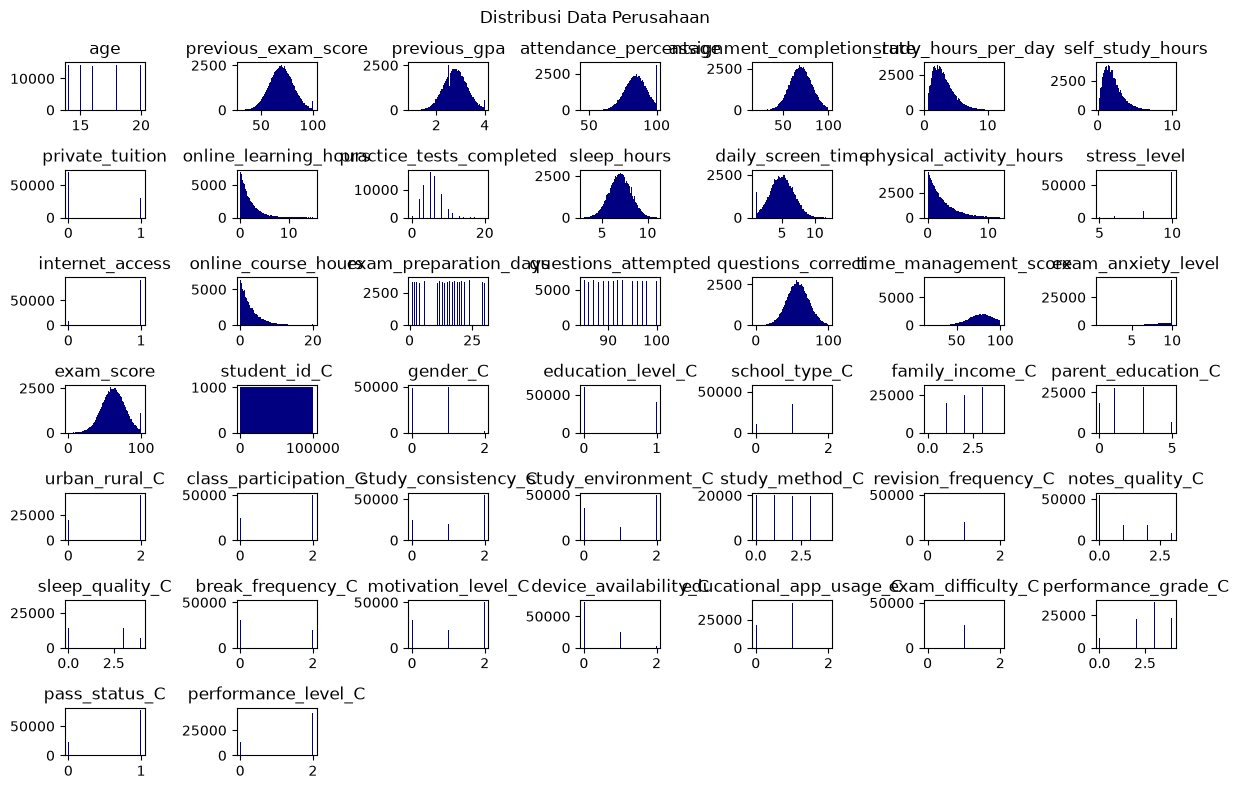

In [21]:
numerik = df_coder.select_dtypes(include=["float64", "int64"])

numerik.hist(color='navy', figsize=(12,8), bins=100, grid=False)
plt.suptitle("Distribusi Data Perusahaan")
plt.tight_layout()
plt.show()

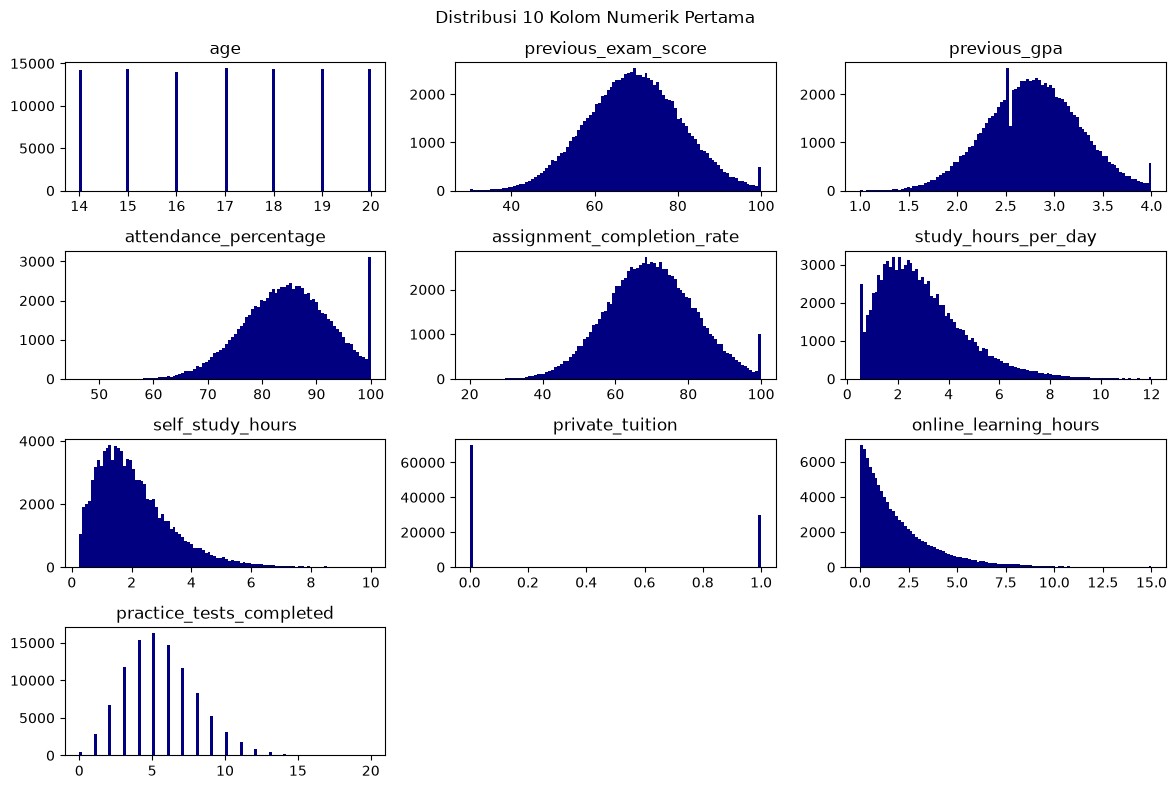

In [22]:
# Memilih hanya 10 kolom numerik pertama
numerik_top10 = df_coder.select_dtypes(include=["float64", "int64"]).iloc[:, :10]

# Membuat histogram khusus 10 kolom tersebut
numerik_top10.hist(color='navy', figsize=(12, 8), bins=100, grid=False)
plt.suptitle("Distribusi 10 Kolom Numerik Pertama")
plt.tight_layout()
plt.show()

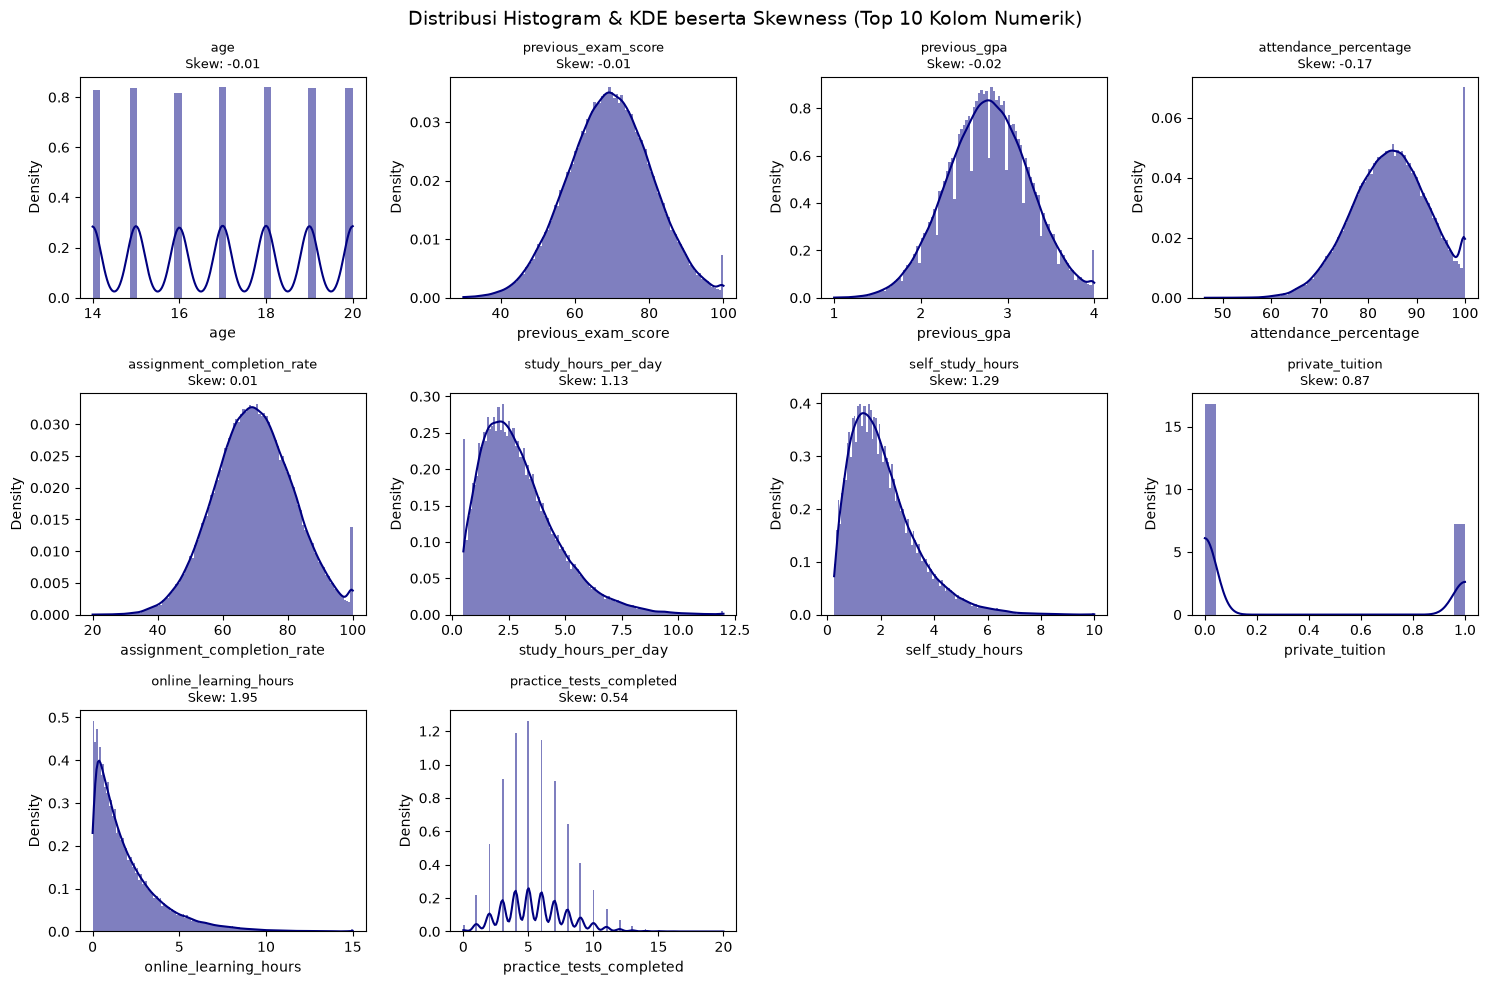

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Memilih 10 kolom numerik pertama dari DataFrame
numerik_top10 = df_coder.select_dtypes(include=["float64", "int64"]).iloc[:, :10]

# 2. Menghitung nilai skewness
skew_values = numerik_top10.skew()

# 3. Membuat subplot grid (3 baris x 4 kolom)
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(numerik_top10.columns):
    # Membuat plot histogram sekaligus garis KDE
    sns.histplot(
        numerik_top10[col].dropna(), 
        color='navy', 
        kde=True, 
        ax=axes[i], 
        stat="density", 
        edgecolor='none'
    )
    
    # Menampilkan nama kolom dan nilai skewness di judul subplot
    sk = skew_values[col]
    axes[i].set_title(f"{col}\nSkew: {sk:.2f}", fontsize=9)
    axes[i].grid(False)

# Menghapus kotak subplot yang kosong (karena grid 12, data hanya 10)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Distribusi Histogram & KDE beserta Skewness (Top 10 Kolom Numerik)", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

### Insight

Berdasarkan hasil visualisasi Histogram dan KDE serta perhitungan *Skewness*, ditemukan bahwa beberapa kolom memiliki distribusi yang mendekati normal, seperti `previous_exam_score`, `assignment_completion_rate`, `sleep_hours`, dan `daily_screen_time`. Sementara itu, kolom `study_hours_per_day`, `self_study_hours`, dan `online_learning_hours` memiliki distribusi menceng ke kanan (*right-skewed*), yang menunjukkan bahwa sebagian besar siswa memiliki nilai relatif rendah dibandingkan sebagian kecil siswa lainnya. Kemencengan tertinggi terdapat pada `online_learning_hours` dengan nilai skewness sebesar 1,95. Hal ini menunjukkan adanya perbedaan pola durasi belajar online antar siswa.

### Heatmap

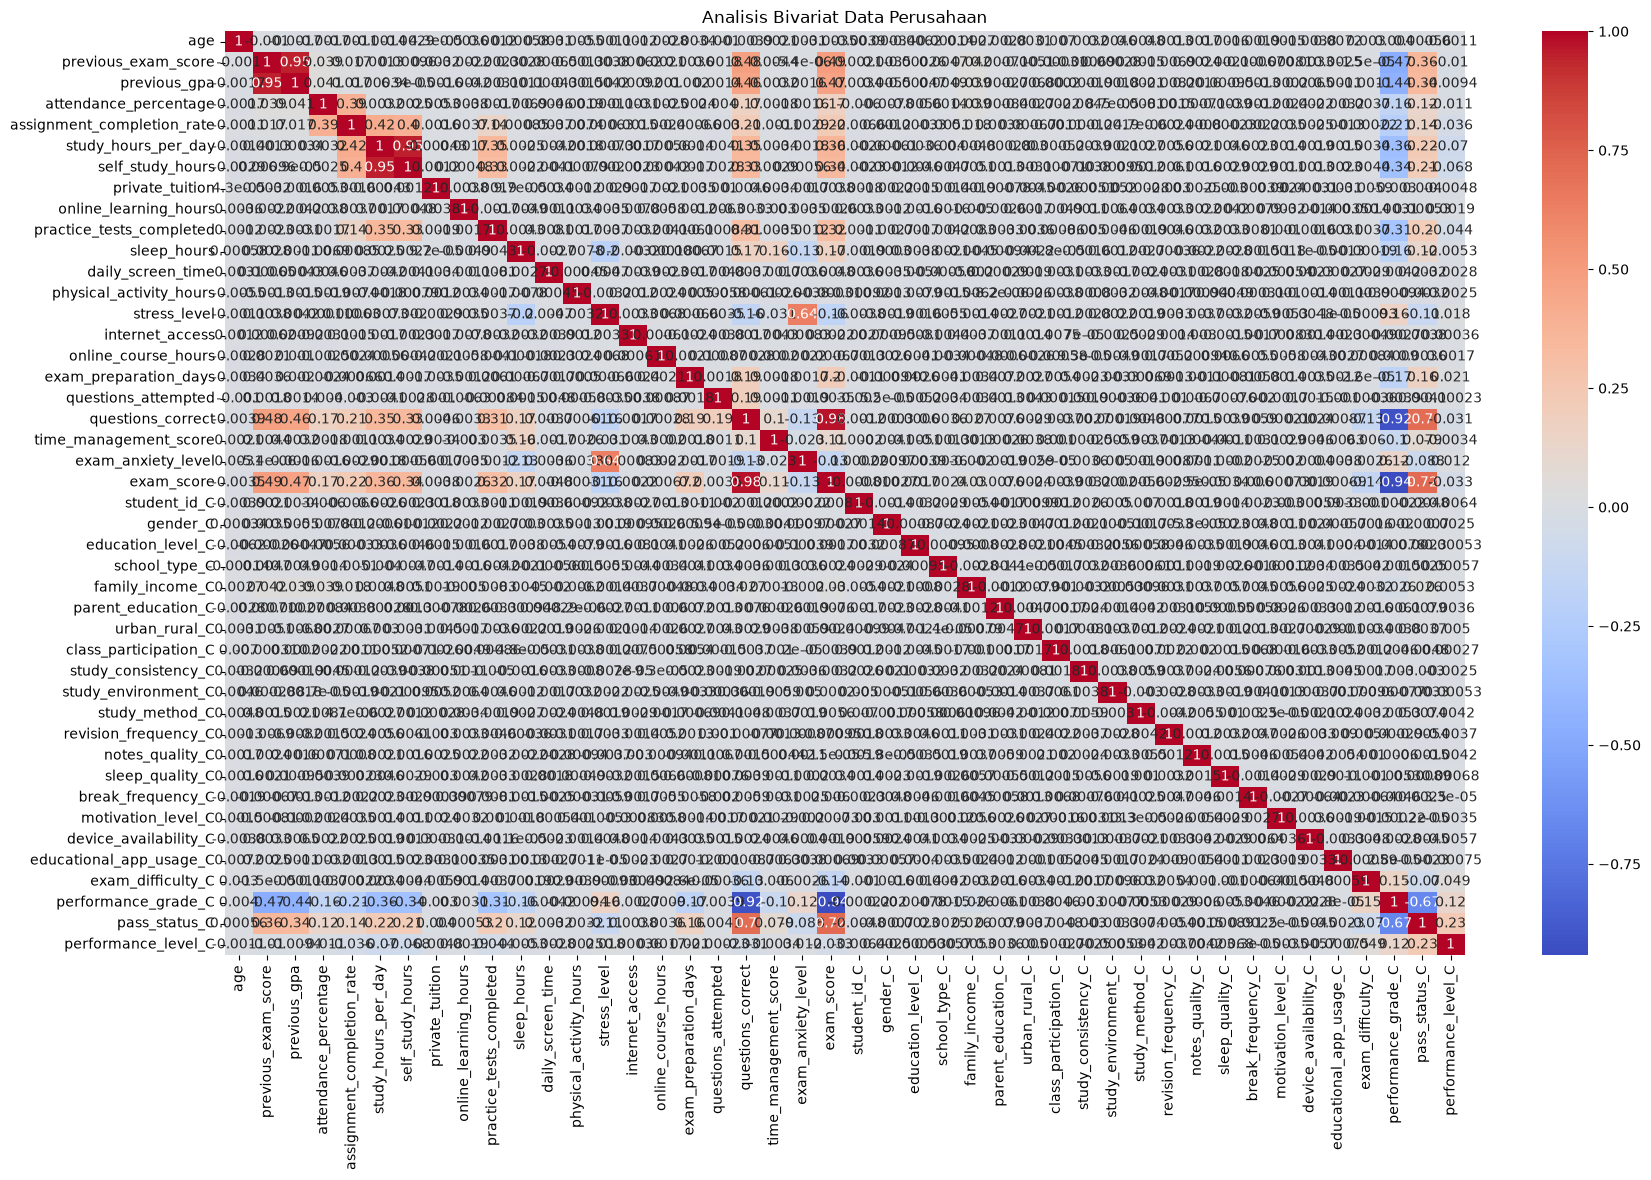

In [24]:
numerik = df_coder.select_dtypes(include=("float64", "int64"))

df_corr = numerik.corr()
plt.figure(figsize=(20, 12))
sns.heatmap(
    df_corr,
    annot=True,
    cmap="coolwarm"
)
plt.title("Analisis Bivariat Data Perusahaan")
plt.show()

In [25]:
numeric_df = df_coder.select_dtypes(include=["number"])

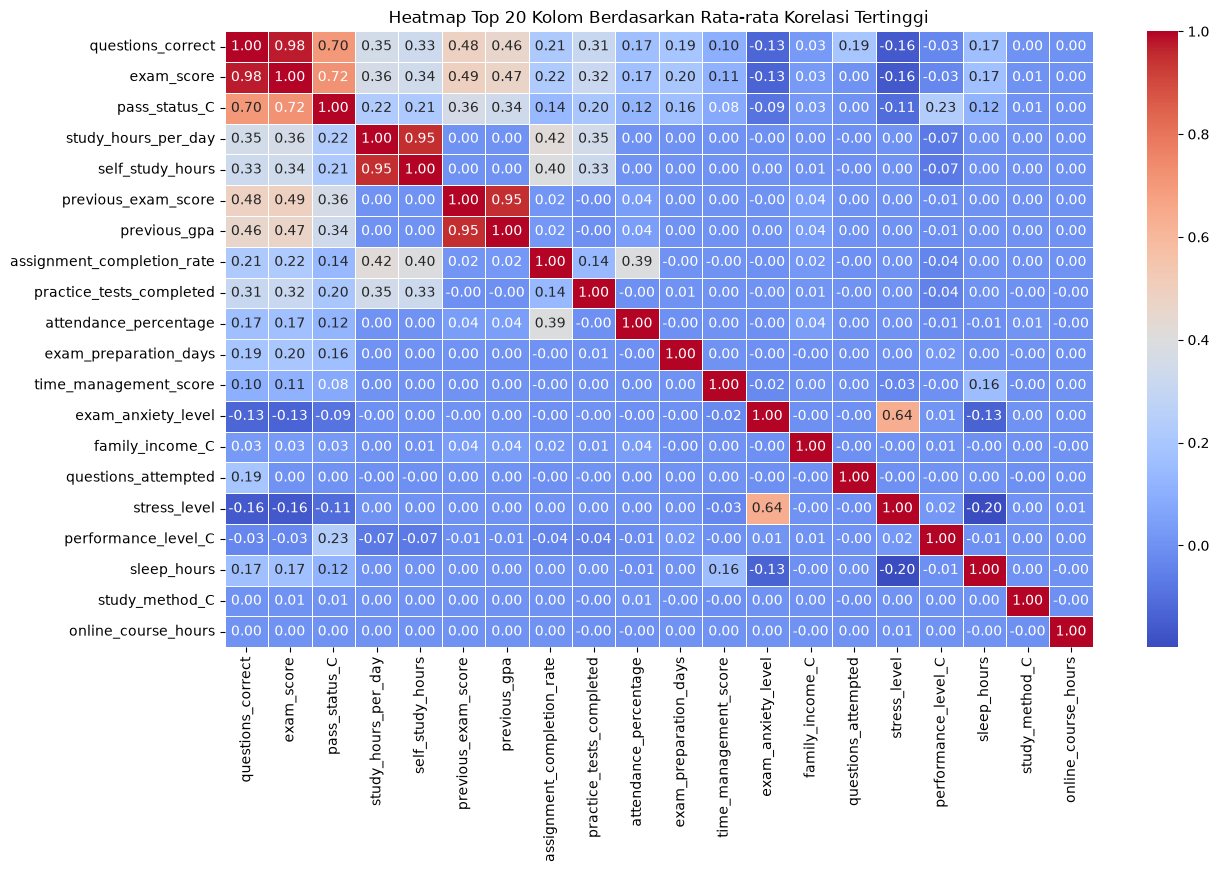

In [26]:
'''
Karena data kolomnya terlalu banyak, maka dari itu dibuat top 20
'''
# Hitung matriks korelasi absolut, lalu cari 20 kolom dengan rata-rata korelasi tertinggi
top_corr_cols = numeric_df.corr().mean().nlargest(20).index
corr_top = numeric_df[top_corr_cols].corr()

# Plot heatmap 10x10
plt.figure(figsize=(14, 8))
sns.heatmap(corr_top, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Heatmap Top 20 Kolom Berdasarkan Rata-rata Korelasi Tertinggi")
plt.show()

In [34]:
'''
Memilih data yang *Fail* saja

'''
df_coder_fail = df_coder[df_coder['pass_status'] == 'Fail']
df_coder_fail

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level,student_id_C,gender_C,education_level_C,school_type_C,family_income_C,parent_education_C,urban_rural_C,class_participation_C,study_consistency_C,study_environment_C,study_method_C,revision_frequency_C,notes_quality_C,sleep_quality_C,break_frequency_C,motivation_level_C,device_availability_C,educational_app_usage_C,exam_difficulty_C,performance_grade_C,pass_status_C,performance_level_C
8,STU_000009,15,Male,Undergraduate,Public,Lower-Middle,Associate,Suburban,61.28,2.43,86.47,70.12,High,2.42,1.65,1,6.23,High,Noisy,Practice Tests,Weekly,7,Excellent,6.55,Good,5.99,1.51,Occasionally,10,Medium,1,Dedicated,Low,2.01,Hard,14,94,35,70.21,8.34,34.44,F,Fail,Low,8,1,1,2,2,0,1,0,0,1,2,2,1,2,1,2,0,1,1,4,0,1
9,STU_000010,16,Female,Undergraduate,Public,Lower-Middle,Associate,Rural,61.33,2.72,89.61,61.53,Low,1.26,0.78,0,2.86,Medium,Noisy,Group Study,Weekly,2,Poor,8.90,Good,1.21,1.59,Frequently,10,Medium,1,Dedicated,Low,8.40,Hard,4,87,34,73.78,8.49,39.05,F,Fail,Low,9,0,1,2,2,0,0,1,2,1,1,2,2,2,0,2,0,1,1,4,0,1
15,STU_000016,16,Male,High School,Public,Middle,Bachelor,Rural,41.12,1.83,99.80,86.47,High,0.50,0.30,0,0.58,High,Noisy,Summarizing,Weekly,5,Average,7.22,Excellent,6.78,1.42,Occasionally,9,Medium,1,Shared,Low,0.53,Hard,14,93,36,96.84,8.47,38.77,F,Fail,Low,15,1,0,2,3,1,0,0,0,1,4,2,0,0,1,2,1,1,1,4,0,1
18,STU_000019,15,Female,High School,Public,Low,Master,Suburban,52.90,2.03,NaN,57.60,Medium,0.87,0.67,0,0.16,Medium,Quiet,Self-Reading,Weekly,4,Average,6.19,NaN,5.54,4.66,Frequently,10,High,1,Dedicated,Moderate,1.16,Hard,3,100,30,NaN,9.85,32.50,F,Fail,Low,18,0,0,2,1,4,1,2,2,2,3,2,0,4,0,0,0,2,1,4,0,1
22,STU_000023,15,Male,High School,Public,Low,High School,Suburban,63.72,2.42,80.78,63.28,Medium,1.46,1.25,0,1.96,High,Quiet,Flashcards,Daily,5,Average,7.37,Fair,3.86,2.48,Frequently,9,Medium,1,Shared,High,3.10,Medium,1,90,18,78.70,8.43,19.76,F,Fail,Low,22,1,0,2,1,3,1,2,0,2,0,0,0,1,0,2,1,0,2,4,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99954,STU_099955,19,Female,High School,Public,Upper-Middle,Doctorate,Urban,57.82,2.38,NaN,60.11,High,3.25,2.42,0,1.59,Medium,Quiet,Practice Tests,Rarely,4,Excellent,8.10,Fair,4.38,1.20,Frequently,10,Medium,1,Dedicated,Low,2.49,Hard,3,87,40,61.86,9.89,44.59,F,Fail,Low,99954,0,0,2,4,2,2,0,2,2,2,1,1,1,0,2,0,1,1,4,0,1
99960,STU_099961,17,Female,Undergraduate,Public,Lower-Middle,Bachelor,Suburban,68.83,2.82,76.79,54.39,Medium,0.80,0.70,0,0.69,Medium,Quiet,Flashcards,Weekly,3,Average,6.28,Fair,2.43,0.15,Frequently,10,Low,1,Dedicated,Low,0.93,Medium,22,92,39,58.95,9.95,43.61,F,Fail,Low,99960,0,1,2,2,1,1,2,2,2,0,2,0,1,0,1,0,1,2,4,0,1
99968,STU_099969,16,Male,Undergraduate,Public,Middle,NaN,Urban,71.27,NaN,95.85,93.85,High,1.45,0.88,1,0.27,Medium,Quiet,Flashcards,Rarely,3,Poor,7.08,Excellent,3.11,2.68,Rarely,10,Medium,1,NaN,High,1.03,Medium,1,95,40,88.93,10.00,45.51,F,Fail,Low,99968,1,1,2,3,5,2,0,2,2,0,1,2,0,2,2,2,0,2,4,0,1
99976,STU_099977,16,Male,High School,Public,Middle,High School,Rural,50.49,2.26,84.73,88.02,Low,2.19,1.59,0,10.76,Medium,Moderate,Flashcards,Weekly,5,Aver

In [35]:
numeric_df_fail = df_coder_fail.select_dtypes(include=["number"])

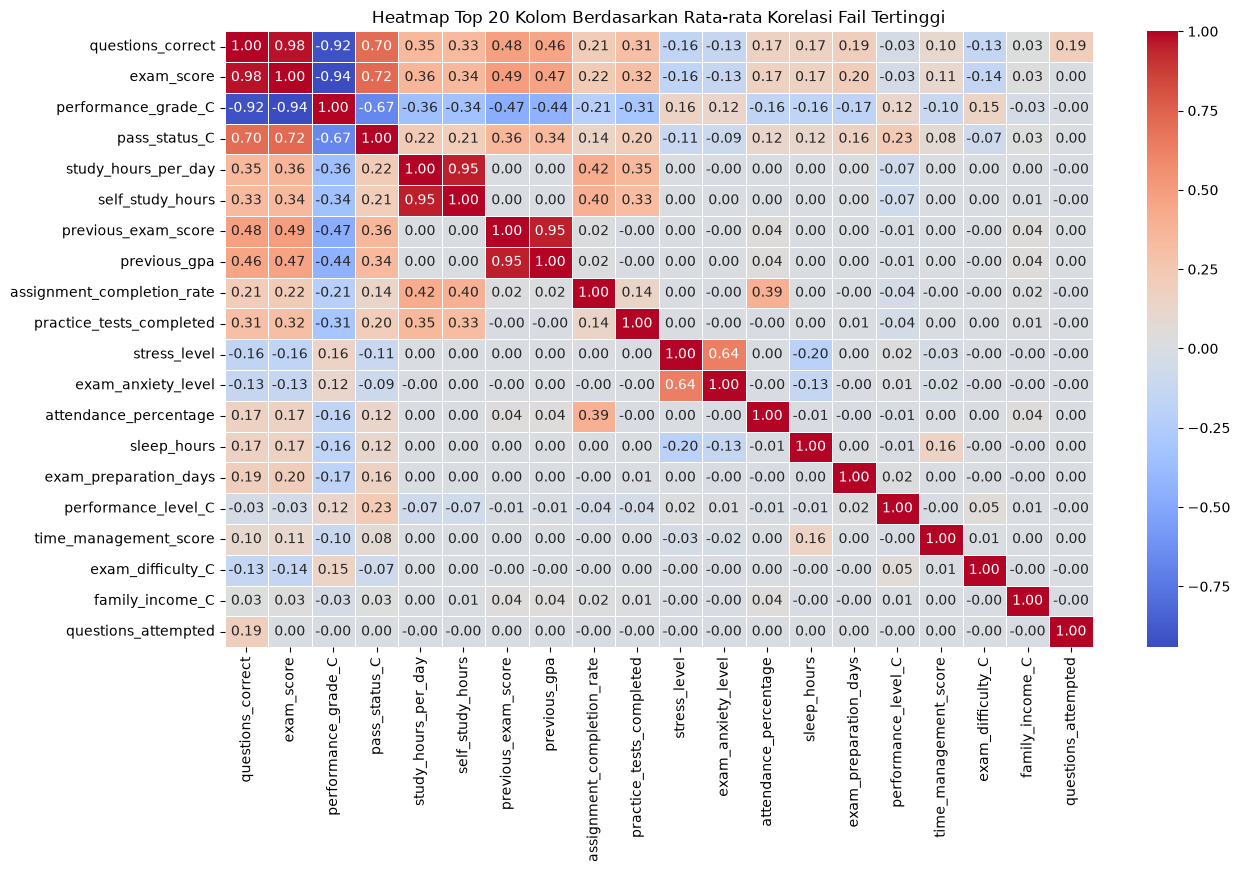

In [36]:
# Hitung matriks korelasi absolut, lalu cari 20 kolom dengan rata-rata korelasi tertinggi
top_corr_cols_fail = numeric_df_fail.corr().mean().nlargest(20).index
corr_top_fail = numeric_df_fail[top_corr_cols].corr()

# Plot heatmap 10x10
plt.figure(figsize=(14, 8))
sns.heatmap(corr_top, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Heatmap Top 20 Kolom Berdasarkan Rata-rata Korelasi Fail Tertinggi")
plt.show()

### Insight

Setelah membuat heatmap Top 20 berdasarkan rata-rata korelasi, ditemukan beberapa variabel yang menarik untuk dianalisis lebih lanjut terhadap `pass_status`, yaitu `study_hours_per_day`, `self_study_hours`, `exam_preparation_days`, `exam_anxiety_level`, `stress_level`, dan `sleep_hours`.

Variabel-variabel tersebut dipilih untuk mengetahui apakah terdapat hubungan antara kebiasaan belajar, kondisi psikologis, kualitas istirahat, serta persiapan ujian dengan status kelulusan siswa (Pass atau Fail).

# Analisa

In [28]:
'''
Membuat Kolom Tambahan
'''
# Membuat kategori setiap variabel
df_copy['stress_category'] = pd.cut(
    df['stress_level'],
    # 0>2(Very Low), 2>4(Low), 4>6(Moderate), 6>8(High), 8>10(Very High)
    bins=[0, 2, 4, 6, 8, 10],
    labels=['Very Low', 'Low', 'Moderate', 'High', 'Very High']
)

df_copy['study_category'] = pd.cut(
    df['study_hours_per_day'],
    bins=[-0.01, 2, 4, 6, float('inf')],
    labels=['Low', 'Moderate', 'High', 'Very High']
)

df['self_study_category'] = pd.cut(
    df['self_study_hours'],
    bins=[-0.01, 1, 2, 3, float('inf')],
    labels=['Low', 'Moderate', 'High', 'Very High']
)

df_copy['sleep_category'] = pd.cut(
    df['sleep_hours'],
    bins=[-0.01, 5, 6, 8, float('inf')],
    labels=['Very Low', 'Low', 'Recommended', 'High']
)

df_copy['assignment_category'] = pd.cut(
    df['assignment_completion_rate'],
    bins=[-0.01, 39, 59, 79, 100],
    labels=['Very Low', 'Low', 'Good', 'Excellent']
)

df_copy['preparation_category'] = pd.cut(
    df['exam_preparation_days'],
    bins=[-0.01, 7, 14, 21, float('inf')],
    labels=['Very Short', 'Short', 'Moderate', 'Long']
)

df_copy

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level,stress_category,study_category,sleep_category,assignment_category,preparation_category
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High,Very High,High,Recommended,Good,Long
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High,High,Moderate,Recommended,Good,Very Short
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium,Very High,Low,Recommended,Good,Long
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium,Very High,Very High,Recommended,Good,Moderate
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low,Very High,Moderate,Recommended,Good,Long
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,NaN,Suburban,78.73,NaN,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium,High,Low,Recommended,Good,Very Short
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,NaN,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High,Very High,Very High,Recommended,Excellent,Long
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,89.57,71.28,Medium,2.45,2.20,0,4.33,High,Moderate,Summarizing,Rarely,5,Average,7.20,Fair,4.80,1.62,Occasionally,9,Medium,1,Dedicated,Moderate,11.91,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium,Very High,Moderate,Recommended,Good,Long
99998,STU_099999,15,Female,High School,Private,High,Master,Rural,74.70,3.06,92.61,69.26,Medium,4.77,3.92,1,0.41,Medium,Quiet,Summarizing,Weekly,7,Average,8.37,Poor,4.40,2.21,Rarely,10,Medium,1,Shared,Moderate,0.55,Medium,28,93,81,100.00,10.00,85.85,A,Pass,High,Very High,High,High,Good,Long


pass_status
Pass    77389
Fail    22611
Name: count, dtype: int64
pass_status
Pass    0.774
Fail    0.226
Name: proportion, dtype: float64


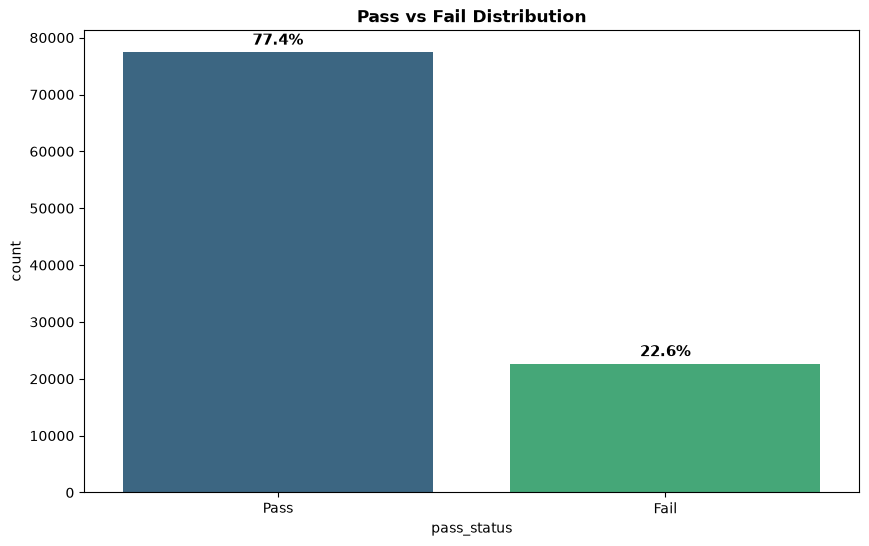

In [29]:
# Target distribution
print(df_copy['pass_status'].value_counts())
print(df_copy['pass_status'].value_counts(normalize=True).round(3))

plt.figure(figsize=(10, 6))

# 1. Buat countplot seperti biasa (gunakan variabel ax untuk menangkap objek plot)
ax = sns.countplot(data=df_copy, x='pass_status', hue='pass_status', palette='viridis')
plt.title("Pass vs Fail Distribution", fontweight='bold')

# 2. Hitung total data untuk pembagi persentase
total = len(df_copy)

# 3. Looping untuk menambahkan teks persentase di atas setiap bar
for p in ax.patches:
    height = p.get_height()
    if height > 0:  # Pastikan bar tidak kosong
        # Hitung persentase
        pct = (height / total) * 100
        
        # Tambahkan teks di atas bar
        ax.annotate(f'{pct:.1f}%', 
                    (p.get_x() + p.get_width() / 2., height), 
                    ha='center', va='bottom', 
                    fontsize=11, fontweight='bold',
                    xytext=(0, 3), textcoords='offset points')

plt.show()

Dari bar chart diatas pada data student_exam_performance ini terdapat 77,4% siswa yang pass(lulus), tetapi ada 22,6% yang fail(tidak lulus), ini bisa jadi pertanyaan dari 100.000 siswa mengapa ada 22,6% yang fail (tidak lulus)

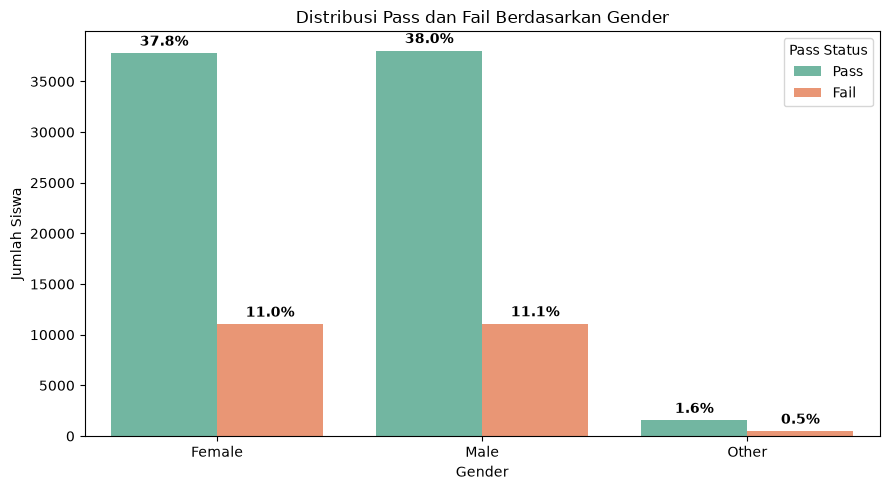

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

# 1. Buat countplot dan simpan ke dalam variabel 'ax'
ax = sns.countplot(
    data=df_copy,
    x='gender',
    hue='pass_status',
    palette='Set2'
)

plt.title('Distribusi Pass dan Fail Berdasarkan Gender')
plt.xlabel('Gender')
plt.ylabel('Jumlah Siswa')
plt.legend(title='Pass Status')

# 2. Ambil total keseluruhan data untuk pembagi persentase
total = len(df_copy)

# 3. Looping untuk menambahkan teks persentase di atas setiap batang
for p in ax.patches:
    height = p.get_height()
    if height > 0:  # Pastikan batang tidak kosong / bernilai 0
        # Hitung persentase terhadap total keseluruhan data
        pct = (height / total) * 100
        
        # Tambahkan teks di atas batang
        ax.annotate(f'{pct:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, fontweight='bold',
                    xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

### Insight
Setelah menentukan julah yang lulus dan tidak, perluh adanya pembanding dengan setiap gender, dan hasilnya 11.1% laki laki lebih banyak tidak lulus ketimbang perempuan yang hanya 11% walau pun hanya beda 0.1% saja. Lalu apakah itu penilaian masing masing gender sama?

In [31]:
'''
Memilih data yang *Fail* saja
'''
df_fail = df_copy[df_copy['pass_status'] == 'Fail']
df_fail

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level,stress_category,study_category,sleep_category,assignment_category,preparation_category
8,STU_000009,15,Male,Undergraduate,Public,Lower-Middle,Associate,Suburban,61.28,2.43,86.47,70.12,High,2.42,1.65,1,6.23,High,Noisy,Practice Tests,Weekly,7,Excellent,6.55,Good,5.99,1.51,Occasionally,10,Medium,1,Dedicated,Low,2.01,Hard,14,94,35,70.21,8.34,34.44,F,Fail,Low,Very High,Moderate,Recommended,Good,Short
9,STU_000010,16,Female,Undergraduate,Public,Lower-Middle,Associate,Rural,61.33,2.72,89.61,61.53,Low,1.26,0.78,0,2.86,Medium,Noisy,Group Study,Weekly,2,Poor,8.90,Good,1.21,1.59,Frequently,10,Medium,1,Dedicated,Low,8.40,Hard,4,87,34,73.78,8.49,39.05,F,Fail,Low,Very High,Low,High,Good,Very Short
15,STU_000016,16,Male,High School,Public,Middle,Bachelor,Rural,41.12,1.83,99.80,86.47,High,0.50,0.30,0,0.58,High,Noisy,Summarizing,Weekly,5,Average,7.22,Excellent,6.78,1.42,Occasionally,9,Medium,1,Shared,Low,0.53,Hard,14,93,36,96.84,8.47,38.77,F,Fail,Low,Very High,Low,Recommended,Excellent,Short
18,STU_000019,15,Female,High School,Public,Low,Master,Suburban,52.90,2.03,NaN,57.60,Medium,0.87,0.67,0,0.16,Medium,Quiet,Self-Reading,Weekly,4,Average,6.19,NaN,5.54,4.66,Frequently,10,High,1,Dedicated,Moderate,1.16,Hard,3,100,30,NaN,9.85,32.50,F,Fail,Low,Very High,Low,Recommended,Low,Very Short
22,STU_000023,15,Male,High School,Public,Low,High School,Suburban,63.72,2.42,80.78,63.28,Medium,1.46,1.25,0,1.96,High,Quiet,Flashcards,Daily,5,Average,7.37,Fair,3.86,2.48,Frequently,9,Medium,1,Shared,High,3.10,Medium,1,90,18,78.70,8.43,19.76,F,Fail,Low,Very High,Low,Recommended,Good,Very Short
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99954,STU_099955,19,Female,High School,Public,Upper-Middle,Doctorate,Urban,57.82,2.38,NaN,60.11,High,3.25,2.42,0,1.59,Medium,Quiet,Practice Tests,Rarely,4,Excellent,8.10,Fair,4.38,1.20,Frequently,10,Medium,1,Dedicated,Low,2.49,Hard,3,87,40,61.86,9.89,44.59,F,Fail,Low,Very High,Moderate,High,Good,Very Short
99960,STU_099961,17,Female,Undergraduate,Public,Lower-Middle,Bachelor,Suburban,68.83,2.82,76.79,54.39,Medium,0.80,0.70,0,0.69,Medium,Quiet,Flashcards,Weekly,3,Average,6.28,Fair,2.43,0.15,Frequently,10,Low,1,Dedicated,Low,0.93,Medium,22,92,39,58.95,9.95,43.61,F,Fail,Low,Very High,Low,Recommended,Low,Long
99968,STU_099969,16,Male,Undergraduate,Public,Middle,NaN,Urban,71.27,NaN,95.85,93.85,High,1.45,0.88,1,0.27,Medium,Quiet,Flashcards,Rarely,3,Poor,7.08,Excellent,3.11,2.68,Rarely,10,Medium,1,NaN,High,1.03,Medium,1,95,40,88.93,10.00,45.51,F,Fail,Low,Very High,Low,Recommended,Excellent,Very Short
99976,STU_099977,16,Male,High School,Public,Middle,High School,Rural,50.49,2.26,84.73,88.02,Low,2.19,1.59,0,10.76,Medium,Moderate,Flashcards,Weekly,5,Average,7.51,Good,5.41,1.83,Rarely,10,Medium,1,Dedicated,High,1.59,Medium,15,93,37,NaN,10.00,38.78,F,Fail,Low,Very High,Moderate,Recommended,Excellent,Moderate


In [32]:
categories = [
    'stress_category',
    'anxiety_category',
    'study_category',
    'self_study_category',
    'sleep_category',
    'assignment_category',
    'preparation_category'
]

for col in categories:

    print(f'\n===== {col.upper()} =====')

    result = pd.crosstab(
        df_copy[col],
        df_copy['pass_status'],
        normalize='index'
    ) * 100

    print(result.round(2))


===== STRESS_CATEGORY =====
pass_status       Fail   Pass
stress_category              
Moderate          8.17  91.83
High             15.15  84.85
Very High        24.67  75.33

===== ANXIETY_CATEGORY =====


KeyError: 'anxiety_category'

In [ ]:
sns.scatterplot(
    data=df_fail,
    x='study_hours_per_day',
    y='assignment_completion_rate',
    alpha=0.5
)

plt.title('Study Hours vs Assignment Completion (Fail)')
plt.xlabel('Study Hours per Day')
plt.ylabel('Assignment Completion Rate')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_fail, 
    x='exam_preparation_days', 
    y='exam_score', 
    alpha=0.3, 
    color='crimson'
)

plt.title('Hari Persiapan Ujian vs Nilai Ujian (Khusus Siswa Fail)', fontsize=12, fontweight='bold')
plt.xlabel('Exam Preparation Days', fontsize=11)
plt.ylabel('Exam Score', fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_fail, 
    x='study_hours_per_day', 
    y='stress_level', 
    alpha=0.3, 
    color='crimson'
)

plt.title('Jam belajar harian vs stress level (Khusus Siswa Fail)', fontsize=12, fontweight='bold')
plt.xlabel('study_hours_per_day', fontsize=11)
plt.ylabel('stress_level', fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
df_copy

# Ekspor Data

In [ ]:
df_copy.to_excel("student_exam_performance_bersih1.xlsx")